#### Step 1: Connect Drive

python



In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).




#### Step 2: Get the processed images

python



In [ ]:
import os
import shutil

DRIVE_DIR = "/content/drive/MyDrive/Processed_SP_ML"
LOCAL_DIR = "/content/Processed_SP_ML"
RESULTS_DIR = "/content/drive/MyDrive/CNN_results"

if not os.path.exists(LOCAL_DIR):
    shutil.copytree(DRIVE_DIR, LOCAL_DIR)

os.makedirs(RESULTS_DIR, exist_ok=True)

print("Processed images:", len(os.listdir(os.path.join(LOCAL_DIR, "images"))))

Processed images: 1032




#### Step 3: Libraries

python



In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torchvision
from torchvision import models
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu




#### Step 4: Load the frozen cut-offs and rebuild the number scaling

python



In [ ]:
IMG_W, IMG_H = 384, 288                      # model input size (same as training)
PREP_W, PREP_H = 512, 384                    # image preparation size (notebook 03)
DIS_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
SEV_COLS = ["FECDgroup", "Folds"]
FECD_GROUP = ["FECD", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]
DIS_DIR = os.path.join(RESULTS_DIR, "final_densenet121")
SEV_DIR = os.path.join(RESULTS_DIR, "severity_densenet121")
CMB_DIR = os.path.join(RESULTS_DIR, "combined_final")

# frozen decision cut-offs
DIS_THR = json.load(open(os.path.join(DIS_DIR, "summary_final.json")))["thresholds"]["Image + numbers"]
sev_sum = json.load(open(os.path.join(SEV_DIR, "summary_severity.json")))
cmb_path = os.path.join(CMB_DIR, "combined_summary.json")
cmb = json.load(open(cmb_path)) if os.path.exists(cmb_path) else {}
SEV_THR = {"FECDgroup": cmb.get("fecd_sev_threshold", sev_sum["severity_thresholds"]["FECDgroup"]),
           "Folds": cmb.get("folds_sev_threshold", sev_sum["severity_thresholds"]["Folds"])}
FECD_SEV_METHOD = cmb.get("fecd_sev_method", "model")

# number scaling: rebuilt from the SAME training rows used in 06a / 07 (identical result)
man = pd.read_csv(os.path.join(LOCAL_DIR, "Image_Manifest_MultiLabel.csv"))
train_df = man[man["Split"] == "train"]
_imp = SimpleImputer(strategy="median").fit(train_df[FEATURES])
_sc = StandardScaler().fit(_imp.transform(train_df[FEATURES]))
scale_tab = lambda f: _sc.transform(_imp.transform(f[FEATURES])).astype(np.float32)

cfg = json.load(open(os.path.join(LOCAL_DIR, "image_config.json")))
FOCUS_LOW = float(cfg["quality_rules"]["low"].split("Q_Focus < ")[1].split()[0])
print("Disease cut-offs :", {k: round(v, 3) for k, v in DIS_THR.items()})
print("Severity cut-offs:", {k: round(v, 3) for k, v in SEV_THR.items()}, "| FECD severity method:", FECD_SEV_METHOD)

Disease cut-offs : {'FECD': 0.434, 'Guttata': 0.387, 'Folds': 0.565, 'PolyPleo': 0.241, 'LowCD': 0.253}
Severity cut-offs: {'FECDgroup': 0.434, 'Folds': 0.277} | FECD severity method: model




> The severity cut-offs are read from what you saved in notebook 08. If you changed the Folds cut-off to 0.35 there, it shows here automatically.

#### Step 5: Load your two final models

python



In [ ]:
def densenet():
    m = models.densenet121(weights=None); dim = m.classifier.in_features; m.classifier = nn.Identity()
    return m, dim

class Fusion(nn.Module):                     # notebook 06a - disease model
    def __init__(self):
        super().__init__()
        self.backbone, dim = densenet(); self.cam_layer = self.backbone.features
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, len(DIS_COLS)))
    def forward(self, x, tab):
        return self.head(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))

class FusionMultiTask(nn.Module):            # notebook 07 - severity model
    def __init__(self):
        super().__init__()
        self.backbone, dim = densenet(); self.cam_layer = self.backbone.features
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 32), nn.ReLU())
        self.shared = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(), nn.Dropout(0.3))
        self.disease_head = nn.Linear(128, len(DIS_COLS))
        self.severity_head = nn.Linear(128, len(SEV_COLS))
    def forward(self, x, tab):
        z = self.shared(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))
        return self.disease_head(z), self.severity_head(z)

dis_model = Fusion().to(DEVICE)
dis_model.load_state_dict(torch.load(os.path.join(DIS_DIR, "Image_plus_numbers.pt"), map_location=DEVICE)); dis_model.eval()
sev_model = FusionMultiTask().to(DEVICE)
sev_model.load_state_dict(torch.load(os.path.join(SEV_DIR, "final_multitask.pt"), map_location=DEVICE)); sev_model.eval()
print("OK - final disease model (06a) and severity model (07) loaded")

OK - final disease model (06a) and severity model (07) loaded




#### Step 6: Image preparation and quality check (same as notebook 03)

python



In [ ]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
T = torchvision.transforms
TF_EVAL = T.Compose([T.ToPILImage(), T.Resize((IMG_H, IMG_W)), T.Grayscale(3), T.ToTensor(),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def check_quality(gray):
    g = cv2.resize(gray, (640, 480), interpolation=cv2.INTER_AREA)
    q = {"std": g.std(), "focus": cv2.Laplacian(g, cv2.CV_64F).var(), "dark": (g < 20).mean(), "saturated": (g > 245).mean()}
    if q["std"] < 5 or q["saturated"] > 0.5: return "Unusable", q
    if q["focus"] < FOCUS_LOW or q["dark"] > 0.45: return "Low", q
    return "OK", q

def prepare_raw(path):
    """Raw specular microscopy image -> same preparation as notebook 03 (resize 512x384 + CLAHE)."""
    raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if raw is None: raise ValueError(f"Cannot read image: {path}")
    quality, q = check_quality(raw)
    prepared = CLAHE.apply(cv2.resize(raw, (PREP_W, PREP_H), interpolation=cv2.INTER_AREA))
    return prepared, quality

def make_tab(ecd, sd, cv, hex_pct, age):
    row = pd.DataFrame([{"ECD_CD_cells_per_mm2": ecd, "ECD_Deficit": None if ecd is None else max(0, 2500 - ecd),
                         "SD": sd, "CV": cv, "HEX_percent": hex_pct, "Donor_Age": age}], dtype=float)
    return torch.tensor(scale_tab(row)), row
print("OK - preparation functions ready")

OK - preparation functions ready




#### Step 7: The full pipeline (predict, report, Grad-CAM)

python



In [ ]:
ORD = {"None": 0, "Mild": 1, "Mod/Sev": 2}

@torch.no_grad()
def run_models(prepared, tab):
    x = TF_EVAL(prepared).unsqueeze(0).to(DEVICE); t = tab.to(DEVICE); xf = torch.flip(x, dims=[3])
    with torch.autocast("cuda", enabled=DEVICE == "cuda"):
        pd_ = (torch.sigmoid(dis_model(x, t)) + torch.sigmoid(dis_model(xf, t))) / 2
        s1, s2 = sev_model(x, t)[1], sev_model(xf, t)[1]
        ps = (torch.sigmoid(s1) + torch.sigmoid(s2)) / 2
    return pd_.float().cpu().numpy()[0], ps.float().cpu().numpy()[0], x

def gradcam(x, tab, j):
    acts, grads = {}, {}
    def hook(m, i, o):
        acts["a"] = o; o.register_hook(lambda g: grads.__setitem__("g", g))
    h = dis_model.cam_layer.register_forward_hook(hook)
    with torch.enable_grad():
        dis_model.zero_grad(); dis_model(x, tab.to(DEVICE))[0, j].backward()
    h.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * acts["a"]).sum(1)).squeeze().detach().float().cpu().numpy()
    cam = cv2.resize(cam, (IMG_W, IMG_H)); return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def analyse(prepared, ecd, sd, cv, hex_pct, age, name="New cornea", quality="OK", show=True):
    tab, row = make_tab(ecd, sd, cv, hex_pct, age)
    P, PS, x = run_models(prepared, tab)
    found = [c for j, c in enumerate(DIS_COLS) if P[j] >= DIS_THR[c]]
    sevs = []
    if any(c in found for c in FECD_GROUP):
        mod = (ecd is not None and ecd < 1600) if FECD_SEV_METHOD == "cd_rule" else PS[0] >= SEV_THR["FECDgroup"]
        sevs.append(("FECD group", "Mod/Sev" if mod else "Mild"))
    if "Folds" in found: sevs.append(("Folds", "Mod/Sev" if PS[1] >= SEV_THR["Folds"] else "Mild"))
    if "Guttata" in found: sevs.append(("Guttata", "Mild (not gradable)"))
    overall = max([s.split()[0] for _, s in sevs], key=lambda s: ORD[s]) if sevs else "None"
    rep = {"Cornea": name, "Image quality": quality,
           "Diseases found": ", ".join(f"{c} ({P[DIS_COLS.index(c)]:.2f})" for c in found) or "None (Normal)",
           "Not found": ", ".join(f"{c} ({P[j]:.2f})" for j, c in enumerate(DIS_COLS) if c not in found) or "-",
           "Severity": ", ".join(f"{d}: {s}" for d, s in sevs) or "-", "Overall severity": overall}
    if show:
        print("=" * 70)
        for k, v in rep.items(): print(f"{k:<17}: {v}")
        if quality != "OK": print("WARNING: image quality is", quality, "- treat this result with caution / re-image")
        print("=" * 70)
        n = 1 + len(found)
        fig, ax = plt.subplots(1, n, figsize=(4.2 * n, 3.4))
        ax = np.atleast_1d(ax); disp = cv2.resize(prepared, (IMG_W, IMG_H))
        ax[0].imshow(disp, cmap="gray"); ax[0].set_title(f"{name}\n(prepared image)", fontsize=9)
        for k, c in enumerate(found, 1):
            ax[k].imshow(disp, cmap="gray"); ax[k].imshow(gradcam(x, tab, DIS_COLS.index(c)), cmap="jet", alpha=0.4)
            ax[k].set_title(f"Grad-CAM: {c} (P={P[DIS_COLS.index(c)]:.2f})", fontsize=9)
        for a in ax: a.axis("off")
        plt.tight_layout(); plt.show()
    rep.update({f"P_{c}": float(P[j]) for j, c in enumerate(DIS_COLS)})
    rep.update({"PSev_FECDgroup": float(PS[0]), "PSev_Folds": float(PS[1])})
    return rep

def analyse_from_dataset(tissue_id, show=True):
    r = man.loc[man["Tissue_ID"] == tissue_id].iloc[0]
    prepared = cv2.imread(os.path.join(LOCAL_DIR, "images", r["Proc_File"]), cv2.IMREAD_GRAYSCALE)   # already prepared in 03
    g = lambda c: None if pd.isna(r[c]) else float(r[c])
    rep = analyse(prepared, g("ECD_CD_cells_per_mm2"), g("SD"), g("CV"), g("HEX_percent"), g("Donor_Age"),
                  name=tissue_id, quality=r.get("Quality", "OK"), show=show)
    if show: print("True label (clinician / dataset):", r["Combination"])
    return rep
print("OK - analyse() ready")

OK - analyse() ready




#### Step 8: Sanity check (this proves the notebook matches your evaluated models)

python



In [ ]:
saved_d = pd.read_csv(os.path.join(DIS_DIR, "test_predictions_all.csv"))
saved_s = pd.read_csv(os.path.join(SEV_DIR, "test_predictions_severity.csv"))
ids = saved_d["Tissue_ID"].sample(10, random_state=0).tolist()
rows = []
for tid in ids:
    rep = analyse_from_dataset(tid, show=False)
    d, s = saved_d.set_index("Tissue_ID").loc[tid], saved_s.set_index("Tissue_ID").loc[tid]
    rows.append({"Tissue_ID": tid,
                 "max diff disease prob": max(abs(rep[f"P_{c}"] - d[f"P_Fus_{c}"]) for c in DIS_COLS),
                 "max diff severity prob": max(abs(rep[f"PSev_{h}"] - s[f"PSev_{h}"]) for h in SEV_COLS)})
chk = pd.DataFrame(rows); display(chk.round(4))
ok = chk[["max diff disease prob", "max diff severity prob"]].max().max() < 0.01
print("PASS - notebook reproduces the evaluated models" if ok else "CHECK - differences above 0.01, tell Claude")

,Tissue_ID,max diff disease prob,max diff severity prob
0,NEB-2020-10-12720 L,0.0000,0.0000
1,NEB-2023-04-14980 R,0.0001,0.0000
2,NEB-2020-12-12849 R,0.0006,0.0001
3,NEB-2020-09-12675 R,0.0014,0.0000
4,NEB-2025-10-17546 L,0.0002,0.0002
5,NEB-2023-05-15011 R,0.0012,0.0002
6,NEB-2023-09-15386 R,0.0009,0.0002
7,NEB-2023-10-15455 R,0.0009,0.0007
8,NEB-2023-05-15084 R,0.0010,0.0019
9,NEB-2024-08-16265 L,0.0006,0.0000


PASS - notebook reproduces the evaluated models




> You should see **PASS**. On GPU, tiny differences like 0.001 are normal and fine.

#### Step 9: Demo A, any cornea from your dataset

python



Some test corneas you can try: ['NEB-2025-10-17541 L', 'NEB-2024-08-16268 R', 'NEB-2024-08-16294 L', 'NEB-2025-11-17629 R', 'NEB-2023-03-14810 R']
Cornea           : NEB-2025-10-17541 L
Image quality    : OK
Diseases found   : None (Normal)
Not found        : FECD (0.00), Guttata (0.02), Folds (0.09), PolyPleo (0.00), LowCD (0.00)
Severity         : -
Overall severity : None


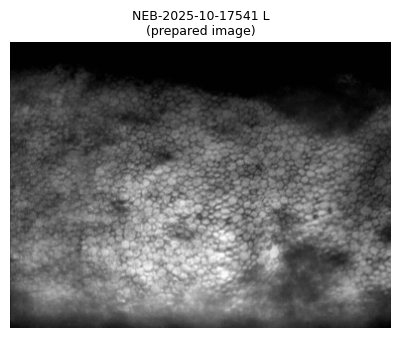

True label (clinician / dataset): Normal


In [ ]:
test_ids = man.loc[man["Split"] == "test", "Tissue_ID"]
print("Some test corneas you can try:", test_ids.sample(5, random_state=1).tolist())
analyse_from_dataset(test_ids.sample(1, random_state=1).iloc[0]);



> To try a specific cornea: `analyse_from_dataset("NEB-2024-08-16268 R")`. Use **test** corneas for demos, because the model never saw them during training.

#### Step 10: Demo B, a new cornea (upload the image and type the numbers)

python



Saving Screenshot 2026-10-14 143122.png to Screenshot 2026-10-14 143122.png
Cornea           : Screenshot 2026-10-14 143122
Image quality    : OK
Diseases found   : FECD (1.00), PolyPleo (1.00), LowCD (1.00)
Not found        : Guttata (0.06), Folds (0.00)
Severity         : FECD group: Mod/Sev
Overall severity : Mod/Sev


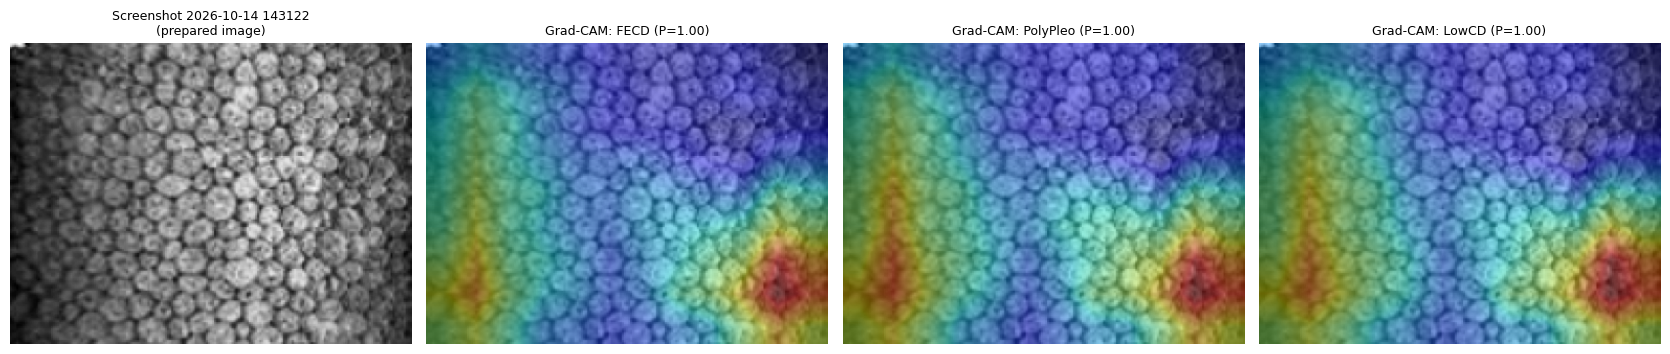

In [ ]:
from google.colab import files
up = files.upload()                                 # choose the _SP.jpg file
img_path = list(up.keys())[0]
prepared, quality = prepare_raw(img_path)
analyse(prepared, ecd=0, sd=0, cv=0, hex_pct=0, age=0,   # <<< type the CellChek values here
        name=os.path.splitext(img_path)[0], quality=quality);

Reference: 824 training images | unseen test distances: median 0.122, 95th 0.171 (warn), 99th 0.198 (reject)


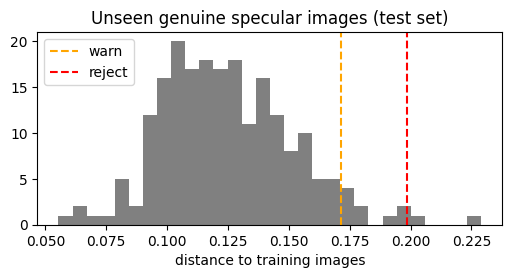

In [ ]:
REF_PATH = os.path.join(CMB_DIR, "ood_reference.npz")

@torch.no_grad()
def embed(prepared):
    x = TF_EVAL(prepared).unsqueeze(0).to(DEVICE)
    f = dis_model.backbone(x).float()
    return torch.nn.functional.normalize(f, dim=1).cpu().numpy()[0]

def knn_distance(e, ref, k=5):
    sims = ref @ e
    return float(1 - np.sort(sims)[-k:].mean())          # 0 = identical to training images, larger = more unusual

if os.path.exists(REF_PATH):
    z = np.load(REF_PATH); REF, d_test = z["ref"], z["d_test"]
else:
    load = lambda f: cv2.imread(os.path.join(LOCAL_DIR, "images", f), cv2.IMREAD_GRAYSCALE)
    REF = np.stack([embed(load(f)) for f in man.loc[man["Split"] == "train", "Proc_File"]])
    d_test = np.array([knn_distance(embed(load(f)), REF) for f in man.loc[man["Split"] == "test", "Proc_File"]])
    np.savez(REF_PATH, ref=REF, d_test=d_test)
OOD_WARN, OOD_REJECT = np.percentile(d_test, 95), np.percentile(d_test, 99)
print(f"Reference: {len(REF)} training images | unseen test distances: median {np.median(d_test):.3f}, "
      f"95th {OOD_WARN:.3f} (warn), 99th {OOD_REJECT:.3f} (reject)")
plt.figure(figsize=(6, 2.5)); plt.hist(d_test, bins=30, color="grey")
plt.axvline(OOD_WARN, color="orange", ls="--", label="warn"); plt.axvline(OOD_REJECT, color="red", ls="--", label="reject")
plt.xlabel("distance to training images"); plt.title("Unseen genuine specular images (test set)"); plt.legend(); plt.show()

In [ ]:
import math
LIMITS = {"ecd": (300, 4500), "sd": (40, 1000), "cv": (15, 90), "hex_pct": (10, 95), "age": (1, 110)}   # physically possible
TRAIN_RANGE = {"ecd": (676, 4484), "cv": (24, 74), "hex_pct": (27, 76), "age": (15, 78)}               # seen in training
NAMES = {"ecd": "ECD", "sd": "SD", "cv": "CV", "hex_pct": "HEX %", "age": "Donor age"}
MIN_SIDE = 300                                                                                          # Konan images are 640x480

def validate_numbers(ecd, sd, cv, hex_pct, age):
    errors, warnings, clean = [], [], {}
    for k, val in dict(ecd=ecd, sd=sd, cv=cv, hex_pct=hex_pct, age=age).items():
        if val is None or (isinstance(val, float) and math.isnan(val)):
            warnings.append(f"{NAMES[k]} missing - filled with the training median"); clean[k] = None; continue
        try:
            val = float(val)
        except (TypeError, ValueError):
            errors.append(f"{NAMES[k]} = {val!r} is not a number"); clean[k] = None; continue
        clean[k] = val
        lo, hi = LIMITS[k]
        if val <= 0:
            errors.append(f"{NAMES[k]} = {val:g} - zero or negative is impossible; use None if unknown")
        elif not lo <= val <= hi:
            errors.append(f"{NAMES[k]} = {val:g} is outside the possible range {lo}-{hi}")
        elif k in TRAIN_RANGE and not TRAIN_RANGE[k][0] <= val <= TRAIN_RANGE[k][1]:
            warnings.append(f"{NAMES[k]} = {val:g} is outside the range seen in training {TRAIN_RANGE[k]}")
    e, s, c = clean["ecd"], clean["sd"], clean["cv"]
    if not errors and None not in (e, s, c):
        expected_sd = c / 100 * 1e6 / e                       # CellChek: SD = CV x mean cell area (within 2% in our data)
        if abs(s / expected_sd - 1) > 0.05:
            errors.append(f"SD {s:g} does not match ECD and CV (expected about {expected_sd:.0f}) - check for a typing mistake")
    if sum(v is None for v in clean.values()) >= 3:
        errors.append("Too many CellChek numbers missing - the model needs them")
    return errors, warnings

def validate_image(path):
    errors, warnings = [], []
    col = cv2.imread(path, cv2.IMREAD_COLOR)
    if col is None: return ["File is not a readable image"], [], None, None
    c = col.astype(np.float32)
    colour = np.abs(c[..., 0] - c[..., 1]).mean() + np.abs(c[..., 1] - c[..., 2]).mean()
    if colour > 3: errors.append(f"Colour image (colour score {colour:.1f}) - specular microscopy images are greyscale")
    h, w = col.shape[:2]
    if min(h, w) < MIN_SIDE:
        errors.append(f"Resolution too low ({w}x{h}; Konan images are 640x480). Enlarging it makes cells look bigger, "
                      f"which would falsely suggest LOW cell density / FECD")
    if not 1.1 <= w / h <= 1.6: warnings.append(f"Unusual shape {w}x{h} (Konan images are 4:3) - may be a screenshot or crop")
    prepared, quality = prepare_raw(path)
    if quality == "Unusable": errors.append("Image quality unusable (blank / saturated)")
    elif quality == "Low": warnings.append("Low image quality (blurred or dark)")
    d = knn_distance(embed(prepared), REF)
    if d > OOD_REJECT: errors.append(f"Does not look like the training specular images (distance {d:.3f} > {OOD_REJECT:.3f})")
    elif d > OOD_WARN: warnings.append(f"Image is unusual compared with training images (distance {d:.3f})")
    return errors, warnings, prepared, quality

# SELF-TEST - you should see REJECTED for the first, third, fourth and fifth lines
for args in [(0, 0, 0, 0, 0), (2650, 143, 38, 55, 65), (2650, 120, 38, 55, 65), (None, None, None, 55, 65), (-5, 143, 38, 55, 65)]:
    e, w = validate_numbers(*args)
    print(f"{str(args):<32} ->", "REJECTED: " + e[0] if e else "OK" + (f" (warning: {w[0]})" if w else ""))

(0, 0, 0, 0, 0)                  -> REJECTED: ECD = 0 - zero or negative is impossible; use None if unknown
(2650, 143, 38, 55, 65)          -> OK
(2650, 120, 38, 55, 65)          -> REJECTED: SD 120 does not match ECD and CV (expected about 143) - check for a typing mistake
(None, None, None, 55, 65)       -> REJECTED: Too many CellChek numbers missing - the model needs them
(-5, 143, 38, 55, 65)            -> REJECTED: ECD = -5 - zero or negative is impossible; use None if unknown


In [ ]:
def safe_analyse(path, ecd, sd, cv, hex_pct, age, name=None, force=False):
    name = name or os.path.splitext(os.path.basename(path))[0]
    ie, iw, prepared, quality = validate_image(path)
    ne, nw = validate_numbers(ecd, sd, cv, hex_pct, age)
    errors, warnings = ie + ne, iw + nw
    print("=" * 70); print(f"INPUT CHECK - {name}")
    for e in errors: print("  REJECTED:", e)
    for w in warnings: print("  WARNING :", w)
    if not errors and not warnings: print("  All input checks passed")
    if errors and not force:
        print("RESULT NOT PRODUCED - fix the inputs above (or use force=True only if you are sure)"); print("=" * 70)
        return None
    if errors: print("  force=True used - result produced despite failed checks, NOT reliable")
    return analyse(prepared, ecd, sd, cv, hex_pct, age, name=name, quality=quality)
print("OK - safe_analyse() ready: use this instead of analyse() for new corneas")

OK - safe_analyse() ready: use this instead of analyse() for new corneas


In [ ]:
res = []
for _, r in man[man["Split"] == "test"].iterrows():
    prepared = cv2.imread(os.path.join(LOCAL_DIR, "images", r["Proc_File"]), cv2.IMREAD_GRAYSCALE)
    d = knn_distance(embed(prepared), REF)
    g = lambda c: None if pd.isna(r[c]) else float(r[c])
    ne, _ = validate_numbers(g("ECD_CD_cells_per_mm2"), g("SD"), g("CV"), g("HEX_percent"), g("Donor_Age"))
    res.append({"image_ok": d <= OOD_REJECT, "numbers_ok": len(ne) == 0})
res = pd.DataFrame(res)
print(f"Genuine test corneas - image accepted: {res['image_ok'].mean():.1%} | numbers accepted: {res['numbers_ok'].mean():.1%} "
      f"| both: {(res['image_ok'] & res['numbers_ok']).mean():.1%}")

Genuine test corneas - image accepted: 98.6% | numbers accepted: 97.1% | both: 95.7%


In [ ]:
from google.colab import files
up = files.upload()
img_path = list(up.keys())[0]
safe_analyse(img_path, ecd=7, sd=0, cv=0, hex_pct=0, age=0);   # <<< CellChek values (None if unknown)

Saving images.jpg to images (4).jpg
INPUT CHECK - images (4)
  REJECTED: ECD = 7 is outside the possible range 300-4500
  REJECTED: SD = 0 - zero or negative is impossible; use None if unknown
  REJECTED: CV = 0 - zero or negative is impossible; use None if unknown
  REJECTED: HEX % = 0 - zero or negative is impossible; use None if unknown
  REJECTED: Donor age = 0 - zero or negative is impossible; use None if unknown
RESULT NOT PRODUCED - fix the inputs above (or use force=True only if you are sure)
